In [1]:
from pathlib import Path
import importlib
import ppv_config
import synthetic_observations

importlib.reload(ppv_config)
importlib.reload(synthetic_observations)

from synthetic_observations import load_field_pair, print_pair_summary
config = ppv_config.config

print("Working directory:", Path.cwd())
print("Input folder:", Path(config["input_dir"]).expanduser().resolve())
print(config)

Working directory: /Users/javier/fake_maps_gs/creating_cubes_V0.1
Input folder: /Users/javier/fake_maps_gs/creating_cubes_V0.1/cubes/N64_L16
{'input_dir': PosixPath('cubes/N64_L16'), 'model_gs': 'stable', 'alpha': 1.5, 'los_axis': 0}


In [2]:
pair = load_field_pair(**config)
print_pair_summary(pair)

Shape (x,y,z): (64, 64, 64)
LOS axis: 0; remaining NumPy axes: (1, 2)

velocity: stable_alpha1.5_3d_velocity_N64_L16.fits
  Model=stable, M3D=1.5, seed=19880127
  Min=-3.781146, max=3.560000
  Mean=0.144235, std=1.004966, variance=1.009956

density: stable_alpha1.5_3d_density_N64_L16.fits
  Model=stable, M3D=1.5, seed=19970221
  Min=-3.670639, max=3.757751
  Mean=-0.023122, std=0.870668, variance=0.758062

Raw base fields only: physical quantities have not yet been assigned.


In [3]:
velocity_base = pair["velocity_base"]
density_base = pair["density_base"]
header_velocity = pair["header_velocity"]
header_density = pair["header_density"]

In [4]:
import numpy as np
import astropy.units as u

importlib.reload(ppv_config)
physical_config = ppv_config.physical_config

# ---------------------------------------------------------
# Velocity: preserve the raw realization, then assign units
# ---------------------------------------------------------
velocity_scale = physical_config["velocity_scale_kms"]

velocity_64 = u.Quantity(
    np.ascontiguousarray(
        pair["velocity_base"] * velocity_scale,
        dtype=np.float64,
    ),
    unit=u.km / u.s,
)

# ---------------------------------------------------------
# Standardize the density-base field
# ---------------------------------------------------------
density_base = pair["density_base"]

density_norm = (
    (density_base - density_base.mean())
    / density_base.std(ddof=0)
)

# ---------------------------------------------------------
# Relative emissivity: dimensionless, with mean = 1
# ---------------------------------------------------------
sig_E = physical_config["sig_E"]

emissivity_relative = np.exp(sig_E * density_norm)
#emissivity_relative /= emissivity_relative.mean()

# ---------------------------------------------------------
# Input to make_ppv
# ---------------------------------------------------------
# Number-density units satisfy the simulator's input convention.
# The numerical field represents our prescribed emissivity weights.
emissivity_64 = u.Quantity(
    np.ascontiguousarray(emissivity_relative, dtype=np.float64),
    unit=u.cm**-3,
)

In [5]:
print("Velocity")
print(f"  Mean:     {velocity_64.mean():.6f}")
print(f"  Std:      {velocity_64.std():.6f}")
print(f"  Variance: {velocity_64.var():.6f}")

print("\nStandardized density-base field")
print(f"  Mean:     {density_norm.mean():.6f}")
print(f"  Std:      {density_norm.std():.6f}")

print("\nRelative emissivity")
print(f"  Mean:          {emissivity_relative.mean():.6f}")
print(f"  Std(log eps):  {np.log(emissivity_relative).std():.6f}")
print(f"  All positive:  {np.all(emissivity_relative > 0)}")
print(f"  All finite:    {np.isfinite(emissivity_relative).all()}")

print("\nEmissivity input to make_ppv")
print(f"  Mean: {emissivity_64.mean():.6f}")
print(f"  Unit: {emissivity_64.unit}")


Velocity
  Mean:     0.144235 km / s
  Std:      1.004966 km / s
  Variance: 1.009956 km2 / s2

Standardized density-base field
  Mean:     -0.000000
  Std:      1.000000

Relative emissivity
  Mean:          1.676913
  Std(log eps):  1.000000
  All positive:  True
  All finite:    True

Emissivity input to make_ppv
  Mean: 1.676913 1 / cm3
  Unit: 1 / cm3


In [6]:
from astropy.constants import m_p, k_B
from turbustat.simulator import make_ppv
from spectral_cube import SpectralCube
from time import perf_counter

importlib.reload(ppv_config)
spectral_config = ppv_config.spectral_config

temperature = spectral_config["temperature_K"] * u.K
particle_mass = spectral_config["particle_mass_mp"] * m_p

sigma_thermal = np.sqrt(
    k_B * temperature / particle_mass
).to(u.km / u.s)

print(f"Thermal dispersion: {sigma_thermal:.3f}")
print("Generating PPV cube...", flush=True)

start = perf_counter()

cube_hdu = make_ppv(
    velocity_64,
    emissivity_64,
    los_axis=pair["los_axis"],
    m=particle_mass,
    T=temperature,
    los_length=spectral_config["los_length_pc"] * u.pc,
    chan_width=spectral_config["channel_width_kms"] * u.km / u.s,
    v_min=spectral_config["v_min_kms"] * u.km / u.s,
    v_max=spectral_config["v_max_kms"] * u.km / u.s,
    threads=1,
)

cube = SpectralCube.read(cube_hdu).with_spectral_unit(u.km / u.s)

print(f"Completed in {perf_counter() - start:.1f} s")
print(f"PPV shape: {cube.shape}  (spectral, spatial, spatial)")
print(f"Intensity unit: {cube.unit}")
print(f"First channel center: {cube.spectral_axis[0]}")
print(f"Last channel center:  {cube.spectral_axis[-1]}")
print(f"Channel spacing: {cube.spectral_axis[1] - cube.spectral_axis[0]}")

/Users/javier/miniconda3/envs/viento/lib/python3.11/site-packages/turbustat/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Thermal dispersion: 9.085 km / s
Generating PPV cube...
Completed in 4.2 s
PPV shape: (240, 64, 64)  (spectral, spatial, spatial)
Intensity unit: K
First channel center: -59.7499999999968 km / s
Last channel center:  59.750000000003205 km / s
Channel spacing: 0.5 km / s


In [8]:
# ---------------------------------------------------------
# Moment maps — retain units and spatial metadata
# ---------------------------------------------------------
moment0 = cube.moment0()
moment1 = cube.moment1()
moment2 = cube.moment2()

# Numerical arrays for the downstream pipeline.
sb = moment0.value
vv = moment1.value
ss = moment2.value

# LOS dispersion, including thermal broadening.
sigma_los_map = np.sqrt(ss)

# ---------------------------------------------------------
# Spatial statistics of the centroid map
# ---------------------------------------------------------
valid = np.isfinite(vv)

if not valid.any():
    raise ValueError("The centroid map contains no finite values.")

sig = np.std(vv[valid])
sig2 = np.var(vv[valid])

# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------
print(f"Moment 0: {sb.shape}")
print(f"Moment 1: {vv.shape}")
print(f"Moment 2: {ss.shape}")

print(f"\nCentroid-map std:      {sig:.6f} km/s")
print(f"Centroid-map variance: {sig2:.6f} (km/s)^2")

print(
    f"\nMean LOS dispersion: "
    f"{np.nanmean(sigma_los_map):.6f} km/s"
)

print("\nChecks")
print(f"  Moment 0 finite:     {np.isfinite(sb).all()}")
print(f"  Moment 0 positive:   {np.all(sb > 0)}")
print(f"  Moment 1 finite:     {np.isfinite(vv).all()}")
print(f"  Moment 2 finite:     {np.isfinite(ss).all()}")
print(f"  Moment 2 nonnegative: {np.all(ss >= 0)}")

Moment 0: (64, 64)
Moment 1: (64, 64)
Moment 2: (64, 64)

Centroid-map std:      0.596878 km/s
Centroid-map variance: 0.356263 (km/s)^2

Mean LOS dispersion: 9.120177 km/s

Checks
  Moment 0 finite:     True
  Moment 0 positive:   True
  Moment 1 finite:     True
  Moment 2 finite:     True
  Moment 2 nonnegative: True


In [9]:
# ---------------------------------------------------------
# Direct LOS moments from the input fields
# ---------------------------------------------------------
los_axis = pair["los_axis"]

weights = emissivity_64.value
vel = velocity_64.to_value(u.km / u.s)

# Integrated emission weights.
sb_direct = np.sum(weights, axis=los_axis)

# Weighted centroid.
vv_direct = (
    np.sum(weights * vel, axis=los_axis)
    / sb_direct
)

# Weighted velocity variance along each sightline.
residual = vel - np.expand_dims(vv_direct, axis=los_axis)

ss_nonthermal = (
    np.sum(weights * residual**2, axis=los_axis)
    / sb_direct
)

# Include the thermal variance used in make_ppv.
thermal_variance = sigma_thermal.to_value(u.km / u.s)**2
ss_direct = ss_nonthermal + thermal_variance

In [10]:
# ---------------------------------------------------------
# Compare PPV moments against direct LOS calculations
# ---------------------------------------------------------
if not (sb.shape == vv.shape == ss.shape == sb_direct.shape):
    raise ValueError("PPV and direct moment maps have different shapes.")

valid = (
    np.isfinite(sb)
    & np.isfinite(vv)
    & np.isfinite(ss)
    & np.isfinite(sb_direct)
    & np.isfinite(vv_direct)
    & np.isfinite(ss_direct)
    & (sb > 0)
    & (sb_direct > 0)
)

if not valid.any():
    raise ValueError("No valid pixels available for comparison.")

# Compare moment-0 morphology, removing its overall conversion factor.
# Both maps have mean = 1 over the same valid pixels.
sb_norm = sb[valid] / sb[valid].mean()
sb_direct_norm = sb_direct[valid] / sb_direct[valid].mean()

differences = {
    "Moment 0 (normalized)": sb_norm - sb_direct_norm,
    "Moment 1 (km/s)": vv[valid] - vv_direct[valid],
    "Moment 2 ((km/s)^2)": ss[valid] - ss_direct[valid],
}

print(f"Compared pixels: {valid.sum()} / {valid.size}\n")
print(f"{'Quantity':26s} {'Mean difference':>16s} {'RMS':>13s} {'Max absolute':>14s}")

for label, difference in differences.items():
    print(
        f"{label:26s} "
        f"{difference.mean():16.6e} "
        f"{np.sqrt(np.mean(difference**2)):13.6e} "
        f"{np.max(np.abs(difference)):14.6e}"
    )

print(f"\nThermal variance: {thermal_variance:.6f}")
print(f"Mean direct nonthermal variance: {ss_nonthermal[valid].mean():.6f}")
print(f"Mean direct total variance:      {ss_direct[valid].mean():.6f}")
print(f"Mean PPV second moment:          {ss[valid].mean():.6f}")

Compared pixels: 4096 / 4096

Quantity                    Mean difference           RMS   Max absolute
Moment 0 (normalized)          5.049672e-17  8.178901e-12   4.739364e-11
Moment 1 (km/s)               -4.708996e-10  1.399771e-09   4.508743e-09
Moment 2 ((km/s)^2)            5.281793e-02  5.596363e-02   3.558537e-01

Thermal variance: 82.543998
Mean direct nonthermal variance: 0.581517
Mean direct total variance:      83.125514
Mean PPV second moment:          83.178332


In [18]:
from pathlib import Path

# Save figures alongside the input FITS cubes.
output_dir = Path(pair["paths"]["velocity"]).parent

print(f"Saving figures to: {output_dir}")

Saving figures to: cubes/N64_L16



sig_E = 0
  Completed in 4.29 s
  Mean relative emissivity: 1.000000
  Mean moment 0:            1.000000
  Centroid-map std:         0.613109
  Centroid-map variance:    0.375902


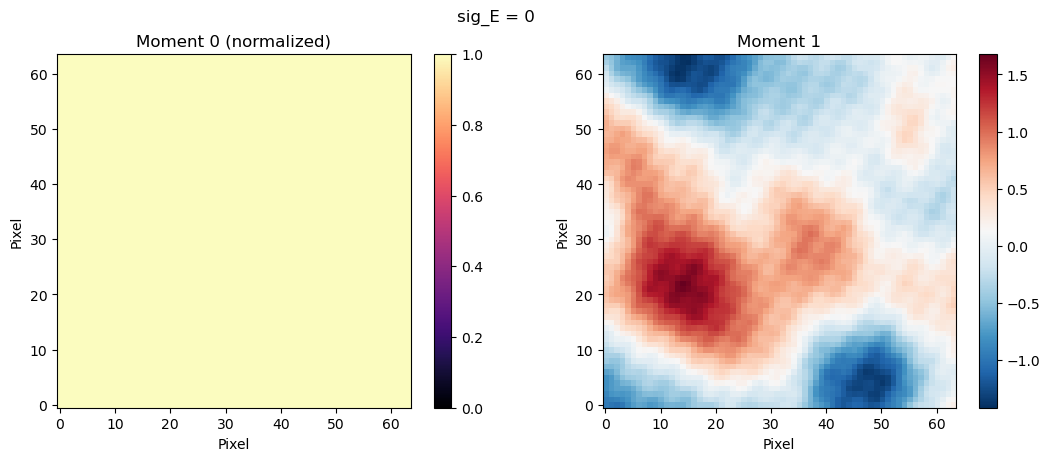

  Saved: stable_alpha1.5_3d_velocity_N64_L16_sigE0_moments.jpg

sig_E = 1
  Completed in 4.10 s
  Mean relative emissivity: 1.000000
  Mean moment 0:            0.269190
  Centroid-map std:         0.596878
  Centroid-map variance:    0.356263


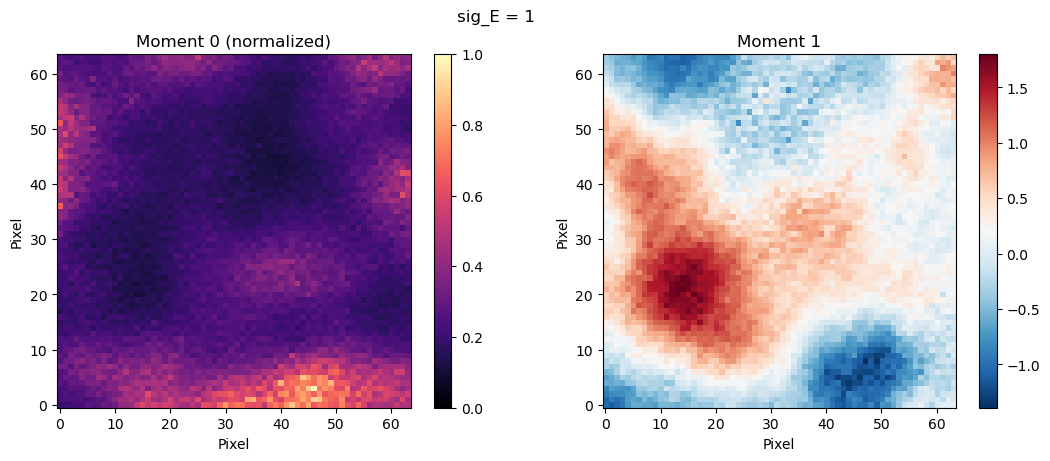

  Saved: stable_alpha1.5_3d_velocity_N64_L16_sigE1_moments.jpg

sig_E = 2
  Completed in 4.08 s
  Mean relative emissivity: 1.000000
  Mean moment 0:            0.067405
  Centroid-map std:         0.646573
  Centroid-map variance:    0.418056


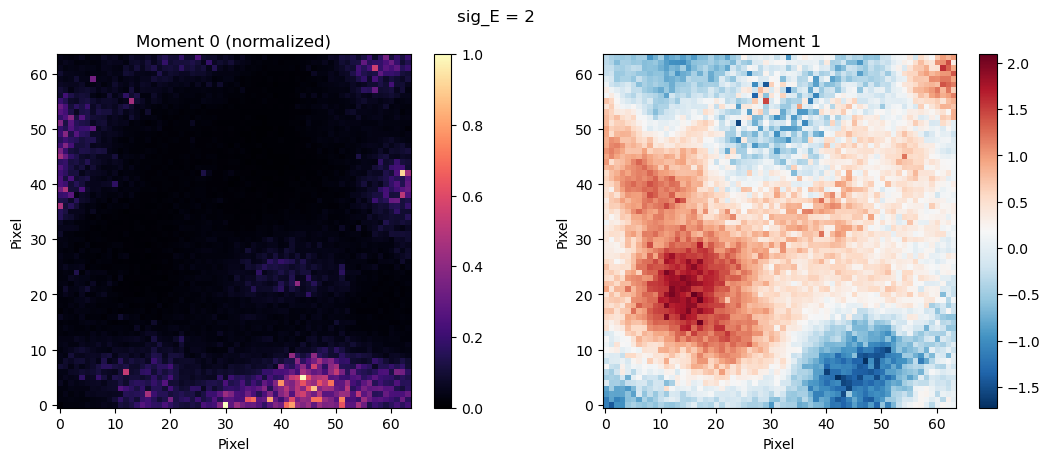

  Saved: stable_alpha1.5_3d_velocity_N64_L16_sigE2_moments.jpg


In [21]:
importlib.reload(ppv_config)
physical_config = ppv_config.physical_config

results = {}

for sig_E in physical_config["sig_E_values"]:
    print(f"\nsig_E = {sig_E:g}")

    # Relative emissivity: mean = 1 for every experiment.
    emissivity_relative = np.exp(sig_E * density_norm)
    emissivity_relative /= emissivity_relative.mean()

    emissivity_64 = u.Quantity(
        np.ascontiguousarray(emissivity_relative, dtype=np.float64),
        unit=u.cm**-3,
    )

    start = perf_counter()

    cube_hdu = make_ppv(
        velocity_64,
        emissivity_64,
        los_axis=pair["los_axis"],
        m=particle_mass,
        T=temperature,
        los_length=spectral_config["los_length_pc"] * u.pc,
        chan_width=spectral_config["channel_width_kms"] * u.km / u.s,
        v_min=spectral_config["v_min_kms"] * u.km / u.s,
        v_max=spectral_config["v_max_kms"] * u.km / u.s,
        threads=1,
    )

    cube = SpectralCube.read(cube_hdu).with_spectral_unit(u.km / u.s)

    moment0 = cube.moment0()
    moment1 = cube.moment1()

    sb = moment0.value
    sb /= sb.max()
    vv = moment1.value

    # Retain the 2D results for comparison and later export.
    results[sig_E] = {
        "sig_E": sig_E,
        "moment0": moment0,
        "moment1": moment1,
        "sb": sb,
        "vv": vv,
        "sig": float(np.nanstd(vv)),
        "sig2": float(np.nanvar(vv)),
    }

    print(f"  Completed in {perf_counter() - start:.2f} s")
    print(f"  Mean relative emissivity: {emissivity_relative.mean():.6f}")
    print(f"  Mean moment 0:            {np.nanmean(sb):.6f}")
    print(f"  Centroid-map std:         {results[sig_E]['sig']:.6f}")
    print(f"  Centroid-map variance:    {results[sig_E]['sig2']:.6f}")

    fig, axes = plt.subplots(
        1, 2,
        figsize=(11, 4.5),
        constrained_layout=True,
    )

    for ax, data, title, cmap, limits in zip(
        axes,
        (sb / sb.max(), vv),
        ("Moment 0 (normalized)", "Moment 1"),
        ("magma", "RdBu_r"),
        ({"vmin": 0, "vmax": 1}, {}),
    ):
        im = ax.imshow(
            data,
            origin="lower",
            cmap=cmap,
            **limits,
        )

        fig.colorbar(im, ax=ax)
        ax.set_title(title)
        ax.set_xlabel("Pixel")
        ax.set_ylabel("Pixel")

    fig.suptitle(f"sig_E = {sig_E:g}")

    output_dir = Path(pair["paths"]["velocity"]).parent
    sample_name = Path(pair["paths"]["velocity"]).stem
    figure_path = output_dir / f"{sample_name}_sigE{sig_E:g}_moments.jpg"

    fig.savefig(figure_path, dpi=300, facecolor="white")
    plt.show()
    plt.close(fig)

    print(f"  Saved: {figure_path.name}")

In [22]:
from pathlib import Path
from astropy.io import fits

output_dir = Path(pair["paths"]["velocity"]).parent
sample_name = Path(pair["paths"]["velocity"]).stem
sample_name = sample_name.replace("_3d_velocity_", "_moments_")

header_velocity = pair["header_velocity"]
header_density = pair["header_density"]

saved_paths = []

for sig_E, entry in results.items():

    filename = f"{sample_name}_sigE{sig_E:g}.fits"
    output_path = output_dir / filename

    # -------------------------------------------------------
    # Primary header: experiment metadata
    # -------------------------------------------------------
    primary = fits.PrimaryHDU()
    header = primary.header

    header["FILE"] = (filename, "FITS file name")
    header["MODEL"] = (header_velocity["MODEL"], "Input covariance model")
    header["M3D"] = (header_velocity["M3D"], "Input model shape parameter")
    header["SIGE"] = (float(sig_E), "Log-emissivity contrast parameter")

    header["SEED1"] = (header_density["SEED"], "Density-base seed")
    header["SEED2"] = (header_velocity["SEED"], "Velocity-base seed")

    header["VELFILE"] = (
        Path(pair["paths"]["velocity"]).name,
        "Input velocity cube",
    )
    header["DENFILE"] = (
        Path(pair["paths"]["density"]).name,
        "Input density-base cube",
    )

    # Input grid and covariance geometry
    for axis, size in zip("XYZ", pair["shape"]):
        header[f"N{axis}"] = (int(size), f"Input grid size along {axis}")

    for key in (
        "LSCALE_X", "LSCALE_Y", "LSCALE_Z",
        "ANGLE_X", "ANGLE_Y", "ANGLE_Z",
        "DX", "DY", "DZ",
    ):
        header[key] = (
            header_velocity[key],
            header_velocity.comments[key],
        )

    header["LOSAXIS"] = (pair["los_axis"], "Input NumPy LOS axis: 0=X, 1=Y, 2=Z")

    # Physical and spectral settings used for this batch
    header["VSCALE"] = (
        physical_config["velocity_scale_kms"],
        "Velocity multiplier in km/s",
    )
    header["TEMP"] = (spectral_config["temperature_K"], "Gas temperature in K")
    header["MASSMP"] = (
        spectral_config["particle_mass_mp"],
        "Particle mass in proton masses",
    )
    header["LOS_PC"] = (
        spectral_config["los_length_pc"],
        "Line-of-sight depth in pc",
    )
    header["CHANWID"] = (
        spectral_config["channel_width_kms"],
        "Requested channel width in km/s",
    )
    header["VMIN"] = (spectral_config["v_min_kms"], "Requested lower edge in km/s")
    header["VMAX"] = (spectral_config["v_max_kms"], "Requested upper edge in km/s")

    # Statistics specific to this sig_E
    header["SIG"] = (entry["sig"], "Centroid-map std in km/s")
    header["SIG2"] = (entry["sig2"], "Centroid-map variance in (km/s)^2")

    header.add_history("Density-base field standardized before exponentiation.")
    header.add_history("Emissivity = exp(sig_E * density_norm), normalized to mean 1.")
    header.add_history("MOM0 exported without display normalization.")

    # -------------------------------------------------------
    # Image extensions: preserve moment headers and units
    # -------------------------------------------------------
    mom0_hdu = fits.ImageHDU(
        data=entry["sb"],
        header=entry["moment0"].header.copy(),
        name="MOM0",
    )

    mom1_hdu = fits.ImageHDU(
        data=entry["vv"],
        header=entry["moment1"].header.copy(),
        name="MOM1",
    )

    fits.HDUList(
        [primary, mom0_hdu, mom1_hdu]
    ).writeto(output_path, overwrite=True)

    saved_paths.append(output_path)
    print(f"Saved: {output_path.name}")

Saved: stable_alpha1.5_moments_N64_L16_sigE0.fits
Saved: stable_alpha1.5_moments_N64_L16_sigE1.fits
Saved: stable_alpha1.5_moments_N64_L16_sigE2.fits


In [23]:
with fits.open(saved_paths[0]) as hdul:
    hdul.info()

    print("\nsig_E:", hdul[0].header["SIGE"])
    print("SIG2:", hdul[0].header["SIG2"])
    print("MOM0 shape:", hdul["MOM0"].data.shape)
    print("MOM1 shape:", hdul["MOM1"].data.shape)

Filename: cubes/N64_L16/stable_alpha1.5_moments_N64_L16_sigE0.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      37   ()      
  1  MOM0          1 ImageHDU        33   (64, 64)   float64   
  2  MOM1          1 ImageHDU        33   (64, 64)   float64   

sig_E: 0.0
SIG2: 0.375902486717481
MOM0 shape: (64, 64)
MOM1 shape: (64, 64)
